In [ ]:
import os
from huggingface_hub import login

hf_token = os.getenv("HF_TOKEN")
login(hf_token)

if hf_token:
    login(hf_token)
    print("Successfully logged in to Hugging Face!")
else:
    print("Hugging Face token not found. Add it in Colab Secrets.")

Hugging Face token not found. Add it in Colab Secrets.


In [ ]:
import sys

!{sys.executable} -m pip install --upgrade pip setuptools wheel
!{sys.executable} -m pip install numpy scikit-learn


!{sys.executable} -m pip install git+https://github.com/AIPHES/emnlp19-moverscore.git

!{sys.executable} -m pip install accelerate rouge-score bert-score nltk torch torchvision pyemd datasets transformers peft "torchao>=0.16.0"

import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('punkt', quiet=True)

  Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
Using cached setuptools-82.0.1-py3-none-any.whl (1.0 MB)
  Attempting uninstall: setuptools
    Found existing installation: setuptools 81.0.0
    Uninstalling setuptools-81.0.0:
      Successfully uninstalled setuptools-81.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.11.0+cu128 requires setuptools<82, but you have setuptools 82.0.1 which is incompatible.
  Cloning https://github.com/AIPHES/emnlp19-moverscore.git to ./tmp/pip-req-build-pkc42kv1
  Running command git clone --filter=blob:none --quiet https://github.com/AIPHES/emnlp19-moverscore.git /tmp/pip-req-build-pkc42kv1
  Resolved https://github.com/AIPHES/emnlp19-moverscore.git to commit 0459a3b3b3bd73baa0cc515a355228ee5a2887e0
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparin

True

In [ ]:
import torch
import gc
import torch.nn as nn
import math
import os
import threading
from typing import Any, Dict, Optional, Tuple, List
from torch.optim import Optimizer
from PIL import Image
from io import BytesIO
import requests


import re
import numpy as np
# Patch for numpy.float deprecation in MoverScore
if not hasattr(np, 'float'):
    np.float = float

from transformers import EvalPrediction
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from sklearn.metrics import f1_score
import nltk
nltk.download('punkt', quiet=True)


from datasets import load_dataset
from transformers import (
    MllamaForConditionalGeneration,
    AutoProcessor,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    TrainerCallback,
)
from moverscore_v2 import get_idf_dict, word_mover_score
from peft import LoraConfig, get_peft_model




def load_image_from_source(image_source):
    """
    Robust image loading for VQAv2 examples.

    HuggingFaceM4/VQAv2's `image` column is already a decoded PIL.Image
    (the loading script embeds the COCO images directly), so this is
    mostly a defensive convert-to-RGB helper with a couple of fallbacks
    for paths/URLs/bytes in case a different source ever gets swapped in.
    """
    try:
        if isinstance(image_source, Image.Image):
            return image_source.convert('RGB') if image_source.mode != 'RGB' else image_source

        if isinstance(image_source, str):
            if image_source.startswith(('http://', 'https://')):
                response = requests.get(image_source, timeout=10)
                response.raise_for_status()
                image = Image.open(BytesIO(response.content))
                return image.convert('RGB') if image.mode != 'RGB' else image

            if os.path.exists(image_source):
                image = Image.open(image_source)
                return image.convert('RGB') if image.mode != 'RGB' else image

            try:
                import base64
                image_data = base64.b64decode(image_source)
                image = Image.open(BytesIO(image_data))
                return image.convert('RGB') if image.mode != 'RGB' else image
            except Exception:
                pass

        if isinstance(image_source, bytes):
            image = Image.open(BytesIO(image_source))
            return image.convert('RGB') if image.mode != 'RGB' else image

        return None

    except Exception as e:
        print(f"Failed to load image: {e}")
        return None


def extract_raw_answers(example):
    """
    Return the list of raw human answer strings for a VQAv2 example, for
    use with the official VQA soft-accuracy metric.

    HuggingFaceM4/VQAv2's `answers` field is a list of dicts like
    {"answer": "net", "answer_confidence": "yes", "answer_id": 1}. This
    also tolerates a flat list-of-strings format in case the dataset
    source is ever swapped for a different VQAv2 mirror.
    """
    answers_field = example.get('answers')
    if not answers_field:
        return []
    raw = []
    for a in answers_field:
        ans = a.get('answer') if isinstance(a, dict) else a
        if ans:
            raw.append(str(ans))
    return raw


class KFACAutogradFunction(torch.autograd.Function):
    """Custom autograd function to capture activations and gradients for K-FAC."""

    @staticmethod
    def forward(ctx, module, output, input):
        ctx.module = module
        ctx.save_for_backward(input.detach())
        return output

    @staticmethod
    def backward(ctx, grad_wrt_output):
        module = ctx.module
        input, = ctx.saved_tensors
        manager = module.grit_manager

        if not module.training:
            return None, grad_wrt_output, None

        tick = manager.cov_update_tick.get(module, 0) + 1
        manager.cov_update_tick[module] = tick
        if tick % manager.config.grit_cov_update_freq != 0:
            return None, grad_wrt_output, None

        with torch.no_grad():
            a = input.reshape(-1, input.shape[-1])
            if a.shape[0] > 0 and 'default' in module.lora_A:
                lora_A_T = module.lora_A['default'].weight.data.T.to(device=a.device, dtype=a.dtype, non_blocking=True)
                projected_a = a @ lora_A_T
                a_cov_sample = projected_a.T @ projected_a

                current_cov = manager.a_covs[module].to(a_cov_sample.device)
                n = manager.num_samples_a[module]
                new_n = n + projected_a.shape[0]
                if new_n > 0:
                    updated_cov = (current_cov.float() * n + a_cov_sample.float()) / new_n
                    manager.a_covs[module].copy_(updated_cov.to(dtype=manager.a_covs[module].dtype))
                    manager.num_samples_a[module] = new_n

            g = grad_wrt_output.reshape(-1, grad_wrt_output.shape[-1])
            if g.shape[0] > 0 and 'default' in module.lora_B:
                lora_B = module.lora_B['default'].weight.data.to(device=g.device, dtype=g.dtype, non_blocking=True)
                projected_g = g @ lora_B
                g_cov_sample = projected_g.T @ projected_g

                current_cov = manager.g_covs[module].to(g_cov_sample.device)
                n = manager.num_samples_g[module]
                new_n = n + projected_g.shape[0]
                if new_n > 0:
                    updated_cov = (current_cov.float() * n + g_cov_sample.float()) / new_n
                    manager.g_covs[module].copy_(updated_cov.to(dtype=manager.g_covs[module].dtype))
                    manager.num_samples_g[module] = new_n

        return None, grad_wrt_output, None


class GRITConfig:
    """Configuration for GRIT training on Llama 3.2 11B Vision Instruct models."""

    def __init__(self):
        self.model_id = "meta-llama/Llama-3.2-11B-Vision-Instruct"
        self.batch_size = 1
        self.gradient_accumulation_steps = 4
        self.num_epochs = 3
        self.learning_rate = 2e-6
        self.precision = "bf16"
        self.max_length = 1024   # change from 1024 from 512

        # LoRA configuration
        self.lora_rank = 8
        self.lora_alpha = 8
        self.lora_dropout = 0.05

        # Llama Vision target modules (language model attention + MLP)
        self.lora_target_modules = [
            "q_proj",      # Query projection
            "k_proj",      # Key projection
            "v_proj",      # Value projection
            "o_proj",      # Output projection
            "gate_proj",   # MLP gate projection
            "up_proj",     # MLP up projection
            "down_proj",   # MLP down projection
        ]

        # Vision encoder LoRA
        self.apply_lora_to_vision = True
        self.vision_lora_modules = [
            "q_proj",      # Vision encoder Q projection
            "k_proj",      # Vision encoder K projection
            "v_proj"      # Vision encoder V projection
            # "o_proj",      # Vision encoder output projection
        ]

        # GRIT hyperparameters
        self.kfac_update_freq = 25
        self.kfac_damping = 0.005
        self.kfac_min_samples = 64
        self.reprojection_freq = 50
        self.reprojection_k = 2
        self.grit_cov_update_freq = 2

        self.use_two_sided_reprojection = True

        self.enable_rank_adaptation = True
        self.rank_adaptation_threshold = 0.99
        self.min_lora_rank = 4

        self.regularizer_warmup_steps = 150
        self.reprojection_warmup_steps = 200
        self.rank_adaptation_start_step = 250
        self.ng_warmup_steps = 75

        self.dataset_name = "HuggingFaceM4/VQAv2"
        self.num_workers = 0
        self.pin_memory = True
        self.drop_last = True

        self.lambda_kfac = 5e-6
        self.lambda_reproj = 5e-5

        self.log_fisher_spectrum = True
        self.log_top_eigs = 8
        self.log_eig_heatmaps = True
        self.log_eigs_bar = False
        self.log_eig_heatmaps_modules = 4
        self.log_eff_rank_on_inversion = False
        self.log_final_eff_rank = True
        self.kfac_inversion_device = 'cpu'

        self.answer_max_length = 128
        self.ignore_index = -100

        self.held_out_test_size = 83


class GRITManager:
    """Manager for GRIT on Llama 3.2 11B Vision Instruct models."""

    def __init__(self, model, config, device):
        self.model = model
        self.config = config
        self.device = device
        self.global_step = 0
        self.backward_step = 0
        self.loss_history = []
        self.loss_history_capacity = 20
        self.last_kfac_update_step = 0
        self.last_reprojection_step = 0
        self.a_covs = {}
        self.g_covs = {}
        self.a_invs = {}
        self.g_invs = {}
        self.num_samples_a = {}
        self.num_samples_g = {}
        self.cov_update_tick = {}
        self.optimized_modules = []
        self.use_supergates = True
        self.supergate_floor = 0.05
        self.supergates = {}
        self.factors_are_ready = False
        self._last_Va_k = {}
        self._last_Vg_k = {}
        self._instrument_model()
        print("GRITManager: Initialization complete for Llama 3.2 11B Vision Instruct model.")
        print(f"Optimizing {len(self.optimized_modules)} LoRA modules across vision + language towers.")

    def _compute_effective_rank(self, cov: torch.Tensor) -> float:
        """Entropy-based effective rank: exp(H(p)), p = λ / trace(cov)."""
        try:
            with torch.no_grad():
                evals = torch.linalg.eigvalsh(cov.float())
                evals = torch.clamp(evals, min=0.0)
                total = float(evals.sum().item())
                if not math.isfinite(total) or total <= 0.0:
                    return 0.0
                p = (evals / total).clamp_min(1e-12)
                entropy = float((-(p * torch.log(p)).sum()).item())
                r_eff = math.exp(entropy)
                n = int(cov.shape[0])
                if not math.isfinite(r_eff):
                    return 0.0
                return float(max(0.0, min(n, r_eff)))
        except Exception:
            return 0.0

    def _instrument_model(self):
        """Instrument both vision and language LoRA modules for Llama Vision."""
        from peft.tuners.lora import LoraLayer
        from peft.tuners.lora.layer import Linear as LoraLinear

        vision_modules = 0
        language_modules = 0

        for name, module in self.model.named_modules():
            if isinstance(module, LoraLayer) and module.r.get('default', 0) > 0 and isinstance(module.base_layer, nn.Linear):
                module.lora_name = name
                module.grit_manager = self

                name_lower = name.lower()
                is_vision = any([
                    'vision_tower' in name_lower,
                    'vision_model' in name_lower,
                    'vision_encoder' in name_lower,
                    'visual' in name_lower and 'language' not in name_lower,
                    name.startswith('model.vision'),
                    name.startswith('vision_tower'),
                ])

                self.num_samples_a[module] = 0
                self.num_samples_g[module] = 0
                self.cov_update_tick[module] = 0

                module.original_forward = module.forward
                def new_forward(self, x=None, *args, **kwargs):
                    if x is None:
                        x = kwargs.get("hidden_states", None)
                        if x is None and len(args) > 0:
                            x = args[0]
                    y = self.original_forward(x, *args, **kwargs)
                    return KFACAutogradFunction.apply(self, y, x)

                module.forward = new_forward.__get__(module, LoraLayer)

                r = module.r['default']
                cov_device = self.device if torch.cuda.is_available() else torch.device('cpu')
                self.a_covs[module] = torch.zeros((r, r), device=cov_device, dtype=torch.float16)
                self.g_covs[module] = torch.zeros((r, r), device=cov_device, dtype=torch.float16)
                self.optimized_modules.append(module)

                if is_vision:
                    vision_modules += 1
                else:
                    language_modules += 1

        print(f"Instrumented {vision_modules} vision modules + {language_modules} language modules")
        print(f"Total LoRA modules with K-FAC: {len(self.optimized_modules)}")

    def _get_adaptive_freq(self, base_freq, min_freq=1, max_freq=1000, window=20):
        if len(self.loss_history) < window:
            return base_freq
        recent_losses = self.loss_history[-window:]
        first_half = sum(recent_losses[:window//2]) / (window//2)
        second_half = sum(recent_losses[window//2:]) / (window//2)
        if second_half < first_half * 0.99:
            new_freq = int(base_freq * 1.5)
        else:
            new_freq = int(base_freq * 0.75)
        return max(min_freq, min(new_freq, max_freq))

    def step(self, loss=None):
        self.global_step += 1
        if loss is not None:
            self.loss_history.append(loss)
            if len(self.loss_history) > self.loss_history_capacity:
                self.loss_history = self.loss_history[-self.loss_history_capacity:]

        if len(self.loss_history) > 10:
            loss_variance = torch.tensor(self.loss_history).var().item()
            self.config.kfac_damping = max(1e-6, min(0.01, 0.001 + math.sqrt(loss_variance)))

        kfac_freq = self._get_adaptive_freq(self.config.kfac_update_freq)
        if self.global_step - self.last_kfac_update_step >= kfac_freq:
            self.update_and_invert_factors()
            self.last_kfac_update_step = self.global_step

        reproj_freq = self._get_adaptive_freq(self.config.reprojection_freq, min_freq=1, max_freq=2000)
        if self.global_step >= int(getattr(self.config, 'reprojection_warmup_steps', 0) or 0) and \
           self.global_step - self.last_reprojection_step >= reproj_freq:
            self.neural_reprojection()
            self.last_reprojection_step = self.global_step

    def update_and_invert_factors(self):
        print(f"\nGRITManager: Inverting K-FAC factors at step {self.global_step}...")
        if not hasattr(self, "_scripted_invert_fn") or self._scripted_invert_fn is None:
            self._scripted_invert_fn = torch.jit.script(jit_invert_tensor_pair)
        scripted_invert_fn = self._scripted_invert_fn

        for module in self.optimized_modules:
            min_samples = getattr(self.config, 'kfac_min_samples', 128)
            if self.num_samples_a.get(module, 0) < min_samples or self.num_samples_g.get(module, 0) < min_samples:
                continue

            inv_device = str(getattr(self.config, 'kfac_inversion_device', 'cpu') or 'cpu')
            if inv_device == 'cuda' and torch.cuda.is_available():
                device_for_inv = torch.device('cuda')
            else:
                device_for_inv = torch.device('cpu')

            a_cov = self.a_covs[module].detach().to(device=device_for_inv, dtype=torch.float32)
            g_cov = self.g_covs[module].detach().to(device=device_for_inv, dtype=torch.float32)

            a_inv, g_inv = scripted_invert_fn(a_cov=a_cov, g_cov=g_cov, kfac_damping=self.config.kfac_damping)
            if a_inv.numel() > 0 and g_inv.numel() > 0:
                self.a_invs[module] = a_inv.to('cpu')
                self.g_invs[module] = g_inv.to('cpu')
            #  SUPERGATES: compute after Fisher inversion
                if self.use_supergates:
                    self.supergates[module] = self.compute_supergates(module)

        self.factors_are_ready = True

    def compute_supergates(self, module):
        """
        Rank-wise gates derived from Fisher eigenvalues.
        Shape: [r]
        """
        cov = self.a_covs[module].detach().float().cpu()

        # Eigenvalues only (directions handled by K-FAC)
        evals = torch.linalg.eigvalsh(cov)
        evals = torch.clamp(evals, min=1e-8)

        # Normalize to probability simplex
        gates = evals / evals.sum()

        # Avoid dead ranks
        gates = torch.clamp(gates, min=self.supergate_floor)
        gates = gates / gates.sum()

        return gates.to(self.device)

    def log_supergate_stats(self):
        print("\n===== SUPERGATE STATS =====")

        if len(self.supergates) == 0:
            print("No supergates found (self.supergates is empty).")
            return

        for module, g in self.supergates.items():
            if g is None or g.numel() == 0:
                continue

            g = g.detach().float().cpu()

            p = g / (g.sum() + 1e-8)
            entropy = (-p * torch.log(p + 1e-8)).sum().item()

            name = getattr(module, "lora_name", module.__class__.__name__)

            print(
                f"{name}: "
                f"mean={g.mean().item():.4f}, "
                f"std={g.std().item():.4f}, "
                f"min={g.min().item():.4f}, "
                f"max={g.max().item():.4f}, "
                f"H={entropy:.4f}"
            )

    def log_final_effective_ranks(self):
        if not getattr(self.config, 'log_final_eff_rank', True):
            return
        try:
            for module in self.optimized_modules:
                a_cov = self.a_covs[module].detach().to(device='cpu', dtype=torch.float32)
                g_cov = self.g_covs[module].detach().to(device='cpu', dtype=torch.float32)
                r_eff_a = self._compute_effective_rank(a_cov)
                r_eff_g = self._compute_effective_rank(g_cov)
                print(f"Fisher/{module.lora_name}/eff_rank_a: {r_eff_a:.4f}")
                print(f"Fisher/{module.lora_name}/eff_rank_g: {r_eff_g:.4f}")
        except Exception:
            pass

    def log_final_raw_ranks(self):
        try:
            for module in self.optimized_modules:
                base_r = int(module.r['default']) if hasattr(module, 'r') and 'default' in module.r else 0
                Va = getattr(self, '_last_Va_k', {}).get(module, None)
                Vg = getattr(self, '_last_Vg_k', {}).get(module, None)
                k_a = int(Va.shape[1]) if Va is not None and Va.numel() > 0 else base_r
                k_b = int(Vg.shape[1]) if Vg is not None and Vg.numel() > 0 else k_a
                print(f"Fisher/{module.lora_name}/final_k_a: {k_a}")
                print(f"Fisher/{module.lora_name}/final_k_b: {k_b}")
        except Exception:
            pass

    def precondition_gradients(self):
        if not self.factors_are_ready:
            return

        with torch.no_grad():
            ng_warmup = int(getattr(self.config, 'ng_warmup_steps', 0) or 0)
            if self.global_step < ng_warmup:
                return

            _total_nat_norm_sq = torch.tensor(0.0, device=self.device)

            for module in self.optimized_modules:
                if module not in self.a_invs or module not in self.g_invs:
                    continue

                lora_a = module.lora_A['default']
                lora_b = module.lora_B['default']

                if (lora_a is None or lora_b is None or
                    lora_a.weight.grad is None or lora_b.weight.grad is None):
                    continue

                a_inv_f32 = self.a_invs[module].to(self.device, dtype=torch.float32)
                g_inv_f32 = self.g_invs[module].to(self.device, dtype=torch.float32)

                grad_b_f32 = lora_b.weight.grad.detach().to(torch.float32)
                preconditioned_b_grad_f32 = grad_b_f32 @ g_inv_f32

                grad_a_f32 = lora_a.weight.grad.detach().to(torch.float32)
                r = module.r['default']
                if r > 0:
                    grad_a_f32 = grad_a_f32.view(r, -1)
                preconditioned_a_grad_f32 = a_inv_f32 @ grad_a_f32
                # ===== SUPERGATES: rank-wise gradient scaling =====
                if self.use_supergates:
                    gates = self.supergates.get(module, None)
                    if gates is not None:
                        # LoRA-A: scale rows (rank dimension)
                        preconditioned_a_grad_f32 *= gates.view(-1, 1)

                        # LoRA-B: scale columns (rank dimension)
                        preconditioned_b_grad_f32 *= gates.view(1, -1)


                _total_nat_norm_sq = _total_nat_norm_sq + preconditioned_a_grad_f32.pow(2).sum() + preconditioned_b_grad_f32.pow(2).sum()

                preconditioned_a_grad_f32 = torch.nan_to_num(preconditioned_a_grad_f32, nan=0.0, posinf=0.0, neginf=0.0)
                preconditioned_b_grad_f32 = torch.nan_to_num(preconditioned_b_grad_f32, nan=0.0, posinf=0.0, neginf=0.0)
                preconditioned_a_grad_f32 = torch.clamp(preconditioned_a_grad_f32, min=-1e6, max=1e6)
                preconditioned_b_grad_f32 = torch.clamp(preconditioned_b_grad_f32, min=-1e6, max=1e6)

                lora_a.weight.grad.copy_(preconditioned_a_grad_f32.to(lora_a.weight.grad.dtype))
                lora_b.weight.grad.copy_(preconditioned_b_grad_f32.to(lora_b.weight.grad.dtype))

                del a_inv_f32, g_inv_f32, grad_a_f32, grad_b_f32, preconditioned_a_grad_f32, preconditioned_b_grad_f32

    def neural_reprojection(self):
        print(f"\nGRITManager: Neural reprojection at step {self.global_step}...")
        initial_params = 0
        final_params = 0

        with torch.no_grad():
            for module in self.optimized_modules:
                if hasattr(module, 'in_features') and hasattr(module, 'out_features'):
                    initial_params += module.r['default'] * (module.in_features + module.out_features)

            for module in self.optimized_modules:
                try:
                    lora_a = module.lora_A['default']
                    lora_b = module.lora_B['default']
                    if lora_a is None or lora_b is None:
                        continue

                    A = lora_a.weight.data.float()
                    B = lora_b.weight.data.float()
                    r = A.shape[0]
                    k = r
                    M = self.a_covs[module].float()

                    if torch.isnan(M).any() or torch.isinf(M).any():
                        final_params += r * (module.in_features + module.out_features)
                        continue

                    min_samples = int(getattr(self.config, 'kfac_min_samples', 128) or 128)
                    if self.num_samples_a.get(module, 0) < min_samples:
                        final_params += r * (module.in_features + module.out_features)
                        continue

                    if self.config.enable_rank_adaptation and r > self.config.min_lora_rank and \
                       self.global_step >= int(getattr(self.config, 'rank_adaptation_start_step', 0) or 0):
                        evals_a, V_a = torch.linalg.eigh(self.a_covs[module].float())
                        order_a = torch.argsort(evals_a, descending=True)
                        V_a = V_a[:, order_a]
                        evals_a = evals_a[order_a]
                        total_energy = torch.sum(evals_a)
                        if total_energy > 1e-6:
                            cumulative_energy = torch.cumsum(evals_a, dim=0) / total_energy
                            k = (cumulative_energy < self.config.rank_adaptation_threshold).sum().item() + 1
                        k = max(k, self.config.min_lora_rank)
                        k = min(k, r)
                        V_a_k = V_a[:, :k]

                        try:
                            g_cov_m = self.g_covs.get(module, None)
                            if getattr(self.config, 'use_two_sided_reprojection', False) and g_cov_m is not None and self.num_samples_g.get(module, 0) >= min_samples:
                                evals_g, V_g = torch.linalg.eigh(g_cov_m.float())
                                order_g = torch.argsort(evals_g, descending=True)
                                V_g_k = V_g[:, order_g][:, :k]
                            else:
                                V_g_k = V_a_k
                        except Exception:
                            V_g_k = V_a_k
                    else:
                        k = min(self.config.reprojection_k, r)
                        evals_a, V_a = torch.linalg.eigh(self.a_covs[module].float())
                        order_a = torch.argsort(evals_a, descending=True)
                        V_a_k = V_a[:, order_a][:, :k]

                        try:
                            g_cov_m = self.g_covs.get(module, None)
                            if getattr(self.config, 'use_two_sided_reprojection', False) and g_cov_m is not None and self.num_samples_g.get(module, 0) >= min_samples:
                                evals_g, V_g = torch.linalg.eigh(g_cov_m.float())
                                order_g = torch.argsort(evals_g, descending=True)
                                V_g_k = V_g[:, order_g][:, :k]
                            else:
                                V_g_k = V_a_k
                        except Exception:
                            V_g_k = V_a_k

                    self._last_Va_k[module] = V_a_k.detach().cpu()
                    self._last_Vg_k[module] = V_g_k.detach().cpu()

                    V_a_k_d = V_a_k.to(device=A.device, dtype=A.dtype, non_blocking=True)
                    V_g_k_d = V_g_k.to(device=B.device, dtype=A.dtype, non_blocking=True)
                    A_proj = V_a_k_d.T @ A
                    B_proj = B @ V_g_k_d
                    A_new = V_a_k_d @ A_proj
                    B_new = B_proj @ V_g_k_d.T
                    lora_a.weight.data.copy_(A_new.to(lora_a.weight.dtype))
                    lora_b.weight.data.copy_(B_new.to(lora_b.weight.dtype))

                    if hasattr(module, 'in_features') and hasattr(module, 'out_features'):
                        final_params += k * (module.in_features + module.out_features)

                except Exception as e:
                    print(f"Error during reprojection for {module.lora_name}: {e}")
                    if hasattr(module, 'in_features') and hasattr(module, 'out_features'):
                        final_params += module.r['default'] * (module.in_features + module.out_features)

        if initial_params > 0:
            param_reduction = initial_params - final_params
            reduction_percent = (param_reduction / initial_params) * 100
            print(f"Neural reprojection: {initial_params:,} -> {final_params:,} ({reduction_percent:.2f}% reduction)")

        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.synchronize()


def jit_invert_tensor_pair(a_cov: torch.Tensor, g_cov: torch.Tensor, kfac_damping: float):
    with torch.no_grad():
        base_damping = float(max(kfac_damping, 1e-6))
        a_cov_f = a_cov.float(); a_cov_f = 0.5 * (a_cov_f + a_cov_f.T)
        g_cov_f = g_cov.float(); g_cov_f = 0.5 * (g_cov_f + g_cov_f.T)
        n_a = int(a_cov_f.shape[0]); n_g = int(g_cov_f.shape[0])
        dev = a_cov_f.device
        I_a = torch.eye(n_a, device=dev); I_g = torch.eye(n_g, device=dev)
        scales = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0]
        for s in scales:
            damp_a = float(base_damping * s)
            damp_g = float(base_damping * s)
            L_a, info_a = torch.linalg.cholesky_ex(a_cov_f + damp_a * I_a)
            L_g, info_g = torch.linalg.cholesky_ex(g_cov_f + damp_g * I_g)
            if int(info_a.item()) == 0 and int(info_g.item()) == 0:
                a_inv = torch.cholesky_inverse(L_a).float()
                g_inv = torch.cholesky_inverse(L_g).float()
                return a_inv, g_inv
        return torch.empty(0, device=dev), torch.empty(0, device=dev)


class GritOptimizer(Optimizer):
    """Wrapper that applies GRIT preconditioning before the underlying step."""

    def __init__(self, optimizer: Optimizer, grit_manager: 'GRITManager'):
        self.optimizer = optimizer
        self.grit_manager = grit_manager

    @property
    def state(self):
        return self.optimizer.state

    @property
    def param_groups(self):
        return self.optimizer.param_groups

    @param_groups.setter
    def param_groups(self, value):
        self.optimizer.param_groups = value

    def step(self, closure=None):
        if self.grit_manager.factors_are_ready and not getattr(self.grit_manager, "_preconditioned", False):
            self.grit_manager.precondition_gradients()
        self.optimizer.step(closure)

    def zero_grad(self, set_to_none: bool = False):
        self.optimizer.zero_grad(set_to_none=set_to_none)

    def add_param_group(self, param_group: dict):
        self.optimizer.add_param_group(param_group)

    def state_dict(self):
        return self.optimizer.state_dict()

    def load_state_dict(self, state_dict: dict):
        self.optimizer.load_state_dict(state_dict)

    def __repr__(self):
        return f"GritOptimizer({self.optimizer.__repr__()})"


class GritCallback(TrainerCallback):
    def __init__(self, grit_manager):
        self.grit_manager = grit_manager

    def on_step_end(self, args, state, control, **kwargs):
        last_loss = state.log_history[-1].get("loss") if state.log_history else None
        self.grit_manager.step(loss=last_loss)
        if self.grit_manager.global_step == 1:
            self.grit_manager.log_supergate_stats()

    def on_train_end(self, args, state, control, **kwargs):
        try:
            self.grit_manager.log_final_effective_ranks()
        except Exception:
            pass
        try:
            self.grit_manager.log_final_raw_ranks()
        except Exception:
            pass
        self.grit_manager.log_supergate_stats()
        torch.save(
            {m.lora_name: g.detach().cpu() for m, g in self.grit_manager.supergates.items()},
            "supergates.pt"
        )


class GritTrainer(Seq2SeqTrainer):
    """Seq2SeqTrainer subclass that injects GRIT preconditioning and regularizers for VQA."""

    def __init__(self, processor, grit_manager, eval_answers_buffer, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.processor = processor
        self.grit_manager = grit_manager
        # Mutable dict shared with make_compute_metrics(), used to pass
        # the raw per-question human answers (popped out of each batch
        # below) through to compute_metrics for the official VQA
        # soft-accuracy formula, since EvalPrediction only carries
        # decoded predictions/labels.
        self.eval_answers_buffer = eval_answers_buffer
        try:
            setattr(self.grit_manager, "_last_grad_clip_cap", float(getattr(self.args, "max_grad_norm", 0.0)))
        except Exception:
            pass
        print("GritTrainer: Initialized with GRIT for Llama 3.2 11B Vision Instruct model.")

    def create_optimizer_and_scheduler(self, num_training_steps: int):
        super().create_optimizer_and_scheduler(num_training_steps)
        if self.optimizer is not None:
            print("Wrapping the optimizer with GRIT preconditioning logic.")
            self.optimizer = GritOptimizer(self.optimizer, self.grit_manager)

    def compute_loss(self, model, inputs, return_outputs=False):
        if 'aspect_ratio_ids' in inputs:
            pass
        else:
            print("MISSING aspect_ratio_ids")

        if 'pixel_values' in inputs:
            pass
        outputs = model(**inputs)
        base_loss = outputs["loss"] if isinstance(outputs, dict) else outputs.loss

        lambda_k = getattr(self.grit_manager.config, "lambda_kfac", 0.0)
        lambda_r = getattr(self.grit_manager.config, "lambda_reproj", 0.0)

        warmup_steps = int(getattr(self.grit_manager.config, "regularizer_warmup_steps", 0) or 0)
        if warmup_steps > 0:
            prog = min(1.0, max(0.0, self.grit_manager.global_step / float(warmup_steps)))
            lambda_k = float(lambda_k) * prog
            lambda_r = float(lambda_r) * prog

        curv_reg = torch.tensor(0.0, device=base_loss.device)
        reproj_reg = torch.tensor(0.0, device=base_loss.device)

        for module in getattr(self.grit_manager, "optimized_modules", []):
            lora_a = module.lora_A['default'] if 'default' in module.lora_A else None
            lora_b = module.lora_B['default'] if 'default' in module.lora_B else None
            if lora_a is None or lora_b is None:
                continue

            A = lora_a.weight
            B = lora_b.weight

            a_cov = self.grit_manager.a_covs.get(module, None)
            g_cov = self.grit_manager.g_covs.get(module, None)

            if a_cov is not None:
                A_f = A.float()
                a_cov_f = a_cov.to(A_f.device, dtype=A_f.dtype)
                curv_reg = curv_reg + ((a_cov_f @ A_f) * A_f).sum()

            if g_cov is not None:
                B_f = B.float()
                g_cov_f = g_cov.to(B_f.device, dtype=B_f.dtype)
                curv_reg = curv_reg + ((B_f @ g_cov_f) * B_f).sum()

            Va_cache = getattr(self.grit_manager, "_last_Va_k", {})
            Vg_cache = getattr(self.grit_manager, "_last_Vg_k", {})
            V_a_k = Va_cache.get(module, None)
            V_g_k = Vg_cache.get(module, None)

            if V_a_k is None and a_cov is not None:
                try:
                    evals, evecs = torch.linalg.eigh(a_cov.float())
                    order = torch.argsort(evals, descending=True)
                    evecs = evecs[:, order]
                    total = torch.clamp(evals.sum(), min=1e-8)
                    threshold = float(self.grit_manager.config.rank_adaptation_threshold)
                    if self.grit_manager.global_step < int(getattr(self.grit_manager.config, 'rank_adaptation_start_step', 0) or 0):
                        k = min(self.grit_manager.config.reprojection_k, A.shape[0])
                    else:
                        k = int((torch.cumsum(evals, 0) / total < threshold).sum().item()) + 1
                    k = max(min(k, A.shape[0]), self.grit_manager.config.min_lora_rank)
                    V_a_k = evecs[:, :k]

                    if V_g_k is None:
                        try:
                            if (getattr(self.grit_manager.config, 'use_two_sided_reprojection', False)
                                and g_cov is not None
                                and self.grit_manager.num_samples_g.get(module, 0) >= int(getattr(self.grit_manager.config, 'kfac_min_samples', 128) or 128)):
                                evals_g, V_gmat = torch.linalg.eigh(g_cov.float())
                                order_g = torch.argsort(evals_g, descending=True)
                                V_g_k = V_gmat[:, order_g][:, :k]
                            else:
                                V_g_k = V_a_k
                        except Exception:
                            V_g_k = V_a_k
                except Exception:
                    V_a_k = None
                    V_g_k = None

            if V_a_k is not None and V_a_k.numel() > 0:
                A_f = A.float(); B_f = B.float()
                device, dtype = A_f.device, A_f.dtype
                V_a_k_d = V_a_k.to(device=device, dtype=dtype, non_blocking=True)
                V_g_k_d = (V_g_k if V_g_k is not None else V_a_k).to(device=device, dtype=dtype, non_blocking=True)
                P_a = V_a_k_d @ V_a_k_d.T
                I_a = torch.eye(P_a.shape[0], device=device, dtype=dtype)
                P_g = V_g_k_d @ V_g_k_d.T
                I_g = torch.eye(P_g.shape[0], device=device, dtype=dtype)
                A_res = (I_a - P_a) @ A_f
                B_res = B_f @ (I_g - P_g)
                reproj_reg = reproj_reg + (A_res.pow(2).sum() + B_res.pow(2).sum())

        loss = base_loss + lambda_k * curv_reg + lambda_r * reproj_reg
        return (loss, outputs) if return_outputs else loss

    def training_step(self, model, inputs, num_items_in_batch=None):
        model.train()
        inputs = self._prepare_inputs(inputs)
        with self.compute_loss_context_manager():
            loss = self.compute_loss(model, inputs)
        if self.args.n_gpu > 1:
            loss = loss.mean()
        self.accelerator.backward(loss)
        return loss.detach() / self.args.gradient_accumulation_steps

    def optimizer_step(self, *args, **kwargs):
        setattr(self.grit_manager, "_preconditioned", False)
        if getattr(self.grit_manager, "factors_are_ready", False):
            self.grit_manager.precondition_gradients()
            setattr(self.grit_manager, "_preconditioned", True)
        return super().optimizer_step(*args, **kwargs)

    def evaluate(self, *args, **kwargs):
        print("\nClearing VRAM before evaluation...")
        gc.collect()
        torch.cuda.empty_cache()
        self.eval_answers_buffer["answers"] = []
        return super().evaluate(*args, **kwargs)

    def prediction_step(
        self,
        model: nn.Module,
        inputs: Dict[str, torch.Tensor],
        prediction_loss_only: bool,
        ignore_keys: Optional[list] = None,
    ) -> Tuple[Optional[torch.Tensor], Optional[torch.Tensor], Optional[torch.Tensor]]:
        has_labels = "labels" in inputs
        if has_labels:
            labels = inputs.pop("labels")
        else:
            labels = None

        vqa_answers_batch = inputs.pop("vqa_answers", None)
        if vqa_answers_batch is not None:
            self.eval_answers_buffer["answers"].extend(vqa_answers_batch)

        input_ids = inputs["input_ids"]
        input_len = input_ids.shape[1]

        with torch.no_grad():
            if prediction_loss_only:
                outputs = model(**inputs)
                loss = outputs.loss if has_labels else None
                return (loss, None, None)

            # Generate (full sequence)
            generated_tokens = model.generate(
                **inputs,
                max_new_tokens=64,
                do_sample=False,
                temperature=0.0,
                pad_token_id=self.processor.tokenizer.pad_token_id,
                eos_token_id=self.processor.tokenizer.eos_token_id,
            )

            # Slice to generated part only (answer)
            generated_tokens = generated_tokens[:, input_len:]

            # Loss (full inputs for compute_loss)
            loss = None
            if has_labels:
                inputs_copy = inputs.copy()
                inputs_copy["labels"] = labels
                loss = self.compute_loss(model, inputs_copy).detach()

        # Labels processing
        if labels is not None:
            if labels.dim() == 3:
                labels = torch.argmax(labels, dim=-1)
            elif labels.dim() == 1:
                batch_size = input_ids.shape[0]
                labels = labels.view(batch_size, -1)

        return loss, generated_tokens, labels



def main():
    config = GRITConfig()

    config.kfac_min_samples = 256
    config.kfac_update_freq = 150
    config.kfac_damping = 0.005
    config.reprojection_warmup_steps = 200
    config.rank_adaptation_start_step = 500
    config.reprojection_freq = 300
    config.use_two_sided_reprojection = True

    print("Loading processor and model for meta-llama/Llama-3.2-11B-Vision-Instruct...")

    processor = AutoProcessor.from_pretrained(
        config.model_id,
        token=hf_token,
    )

    processor.tokenizer.padding_side = "left"



    if processor.tokenizer.pad_token is None:
        processor.tokenizer.pad_token = processor.tokenizer.eos_token



    model = MllamaForConditionalGeneration.from_pretrained(
        config.model_id,
        device_map="auto",
        token=hf_token,
        torch_dtype=torch.bfloat16,
        trust_remote_code=True,
        attn_implementation="sdpa",
    )

    print(model.config._attn_implementation)
    model.gradient_checkpointing_enable()

    # Target modules for Llama Vision
    target_modules = config.lora_target_modules.copy()

    lora_config = LoraConfig(
        r=config.lora_rank,
        lora_alpha=config.lora_alpha,
        target_modules=target_modules,
        lora_dropout=config.lora_dropout,
        bias="none",
        task_type="CAUSAL_LM",
        inference_mode=False,
        use_rslora=True,
    )

    model = get_peft_model(model, lora_config)
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())

    print(f"Trainable params: {trainable_params:,}")
    print(f"Total params: {total_params:,}")
    print(f"Percentage: {100 * trainable_params / total_params:.3f}%")

    model.enable_input_require_grads()
    model.config.use_cache = False

    from datasets import load_dataset, Dataset

    print("Streaming VQAv2 dataset (no full download)...")

    streamed = load_dataset(config.dataset_name, trust_remote_code=True, streaming=True)

    train_stream = streamed["train"].shuffle(seed=42, buffer_size=1000)
    train_examples = list(train_stream.take(665))


    val_stream = streamed["validation"].shuffle(seed=42, buffer_size=1000)
    val_examples = list(val_stream.take(83 + config.held_out_test_size))

    train_dataset = Dataset.from_list(train_examples)
    val_dataset = Dataset.from_list(val_examples[:83])
    test_dataset = Dataset.from_list(val_examples[83:])

    print(f"Final splits → Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")


    def tokenize_vqa(example):
        """Process VQAv2 examples with robust image loading for Llama Vision."""
        try:
            if 'image' not in example or example['image'] is None:
                return None

            image = load_image_from_source(example['image'])

            if image is None:
                return None

            if not isinstance(image, Image.Image):
                return None
            if image.mode != 'RGB':
                image = image.convert('RGB')

            question = (example.get('question') or '').strip()
            question_tokens = processor.tokenizer.encode(
                question,
                add_special_tokens=False
            )

            question_tokens = question_tokens[:80]

            question = processor.tokenizer.decode(
                question_tokens,
                skip_special_tokens=True
            )

            answer = (example.get('multiple_choice_answer') or '').strip()
            answer_tokens_full = processor.tokenizer.encode(
                answer,
                add_special_tokens=False
            )

            answer_tokens_full = answer_tokens_full[:120]

            answer = processor.tokenizer.decode(
                answer_tokens_full,
                skip_special_tokens=True
            )

            if not question or not answer:
                return None

            # VQAv2 has no `context` field, so the prompt is just the question.
            text_content = f"Question: {question}\n\nProvide a concise answer."

            messages = [
                {
                    "role": "user",
                    "content": [
                        {"type": "image"},
                        {"type": "text", "text": text_content}
                    ],
                }
            ]

            text_prompt = processor.apply_chat_template(
                messages,
                add_generation_prompt=True,
                tokenize=False,
            )

            inputs = processor(
                text=text_prompt,
                images=image,
                return_tensors="pt",
                add_special_tokens=False,
                truncation=True,
                max_length=config.max_length,
            )



            # Tokenize answer separately
            answer_tokens = processor.tokenizer(
                answer,
                add_special_tokens=False
            )['input_ids']

            answer_tokens = torch.tensor(answer_tokens, dtype=torch.long)

            # Prepare tensors
            input_ids = inputs['input_ids'].squeeze(0)
            attention_mask = inputs['attention_mask'].squeeze(0)


            if not isinstance(input_ids, torch.Tensor):
                input_ids = torch.tensor(input_ids, dtype=torch.long)
            if not isinstance(attention_mask, torch.Tensor):
                attention_mask = torch.tensor(attention_mask, dtype=torch.long)
            if not isinstance(answer_tokens, torch.Tensor):
                answer_tokens = torch.tensor(answer_tokens, dtype=torch.long)

            # Create labels correctly
            labels = torch.full_like(input_ids, -100)

            labels[input_ids == processor.tokenizer.pad_token_id] = -100

            answer_len = min(answer_tokens.shape[0], input_ids.shape[0])

            if answer_len > 0:
                labels[-answer_len:] = answer_tokens[-answer_len:]

            output = {
                'input_ids': input_ids,
                'attention_mask': attention_mask,
                'labels': labels,
                'vqa_answers': extract_raw_answers(example),
            }


            if 'pixel_values' in inputs:
                pixel_values = inputs['pixel_values']

                if isinstance(pixel_values, torch.Tensor):
                    if pixel_values.dim() >= 2 and pixel_values.shape[0] == 1:
                        pixel_values = pixel_values.squeeze(0)

                    output['pixel_values'] = pixel_values

                elif isinstance(pixel_values, list) and len(pixel_values) > 0:
                    if isinstance(pixel_values[0], torch.Tensor):
                        output['pixel_values'] = (
                            pixel_values[0]
                            if len(pixel_values) == 1
                            else torch.cat(pixel_values, dim=0)
                        )

            if 'aspect_ratio_ids' in inputs:
                output['aspect_ratio_ids'] = inputs['aspect_ratio_ids']

            if 'aspect_ratio_mask' in inputs:
                output['aspect_ratio_mask'] = inputs['aspect_ratio_mask']

            if 'cross_attention_mask' in inputs:
                output['cross_attention_mask'] = inputs['cross_attention_mask']


            for key in ['input_ids', 'attention_mask', 'labels']:
                if key in output and not isinstance(output[key], torch.Tensor):
                    print(f"ERROR: {key} is not a tensor: {type(output[key])}")
                    return None

            return output

        except Exception as e:
            print(f"Error processing example: {e}")
            import traceback
            traceback.print_exc()
            return None

    print("Tokenizing datasets...")
    print("Processing training data...")
    tokenized_train_dataset = train_dataset.map(
        tokenize_vqa,
        remove_columns=train_dataset.column_names,
        num_proc=None,
        desc="Processing training data",
        load_from_cache_file=False,
        writer_batch_size=1
    )

    print("Filtering valid training samples...")
    tokenized_train_dataset = tokenized_train_dataset.filter(
        lambda x: x is not None and 'input_ids' in x and 'labels' in x,
        desc="Filtering training data"
    )

    print("Processing validation data...")
    tokenized_val_dataset = val_dataset.map(
        tokenize_vqa,
        remove_columns=val_dataset.column_names,
        num_proc=None,
        desc="Processing validation data",
        load_from_cache_file=False,
        writer_batch_size=1
    )

    print("Filtering valid validation samples...")
    tokenized_val_dataset = tokenized_val_dataset.filter(
        lambda x: x is not None and 'input_ids' in x and 'labels' in x,
        desc="Filtering validation data"
    )

    print("Processing test data (held out from validation)...")
    tokenized_test_dataset = test_dataset.map(
        tokenize_vqa,
        remove_columns=test_dataset.column_names,
        num_proc=None,
        desc="Tokenizing test",
        load_from_cache_file=False,
        writer_batch_size=1
    )

    print("Filtering valid test samples...")
    tokenized_test_dataset = tokenized_test_dataset.filter(
        lambda x: x is not None and 'input_ids' in x and 'labels' in x,
        desc="Filtering test data"
    )

    train_len = len(tokenized_train_dataset)
    val_len = len(tokenized_val_dataset)
    test_len = len(tokenized_test_dataset)

    if train_len == 0:
        raise ValueError(
            "No training samples after processing. "
            "Possible causes: images not loading correctly, dataset format incompatible, "
            "or all examples failed validation."
        )

    print(f"\nSuccessfully processed datasets:")
    print(f"Training samples: {train_len}")
    print(f"Validation samples: {val_len}")
    print(f"Test samples: {test_len}")

    eff_batch = config.batch_size * config.gradient_accumulation_steps
    total_steps = math.ceil(train_len / eff_batch) * config.num_epochs

    print(f"\nTraining Configuration:")
    print(f"Total training steps: {total_steps}")
    print(f"Effective batch size: {eff_batch}")
    print(f"Steps per epoch: {math.ceil(train_len / eff_batch)}")

    training_args = Seq2SeqTrainingArguments(
        output_dir="./results_vqa_grit_llama",
        per_device_train_batch_size=config.batch_size,
        per_device_eval_batch_size=config.batch_size,
        gradient_accumulation_steps=config.gradient_accumulation_steps,
        num_train_epochs=config.num_epochs,
        learning_rate=config.learning_rate,
        bf16=(config.precision == "bf16"),
        fp16=(config.precision == "fp16"),
        max_grad_norm=1.5,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        dataloader_num_workers=config.num_workers,
        dataloader_drop_last=config.drop_last,
        remove_unused_columns=False,
        dataloader_pin_memory=False,
        report_to="none",
        save_strategy="epoch",
        eval_strategy="epoch",
        save_total_limit=2,
        logging_steps=50,
        warmup_steps=100,
        optim="adamw_torch",
        load_best_model_at_end=True,
        metric_for_best_model="loss",
    )

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\nInitializing GRIT on device: {device}")
    grit_manager = GRITManager(model, config, device)


    def collate_fn(batch):
        """Custom collator for Llama Vision inputs with proper batching."""
        batch = [b for b in batch if b is not None and isinstance(b, dict) and 'input_ids' in b]

        if len(batch) == 0:
            print("WARNING: Empty batch after filtering - creating dummy batch")
            dummy_input_ids = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_attention_mask = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_labels = torch.full((1, config.max_length), config.ignore_index, dtype=torch.long)
            dummy_pixel_values = torch.zeros((1, 1, 4, 3, 560, 560))
            dummy_aspect_ratio_ids = torch.tensor([[2]])
            dummy_aspect_ratio_mask = torch.tensor([[[1, 1, 0, 0]]])
            dummy_cross_attention_mask = torch.tensor([[[[1, 1, 0, 0]]]])

            return {
                'input_ids': dummy_input_ids,
                'attention_mask': dummy_attention_mask,
                'pixel_values': dummy_pixel_values,
                'aspect_ratio_ids': dummy_aspect_ratio_ids,
                'aspect_ratio_mask': dummy_aspect_ratio_mask,
                'cross_attention_mask': dummy_cross_attention_mask,
                'labels': dummy_labels,
            }

        try:
            # Convert non-tensor items to tensors
            for i, item in enumerate(batch):
                for key in ['input_ids', 'attention_mask', 'labels']:
                    if key in item and not isinstance(item[key], torch.Tensor):
                        batch[i][key] = torch.tensor(item[key], dtype=torch.long)

            # Pad sequences
            input_ids = torch.nn.utils.rnn.pad_sequence(
                [b['input_ids'] for b in batch],
                batch_first=True,
                padding_value=processor.tokenizer.pad_token_id
            )

            attention_mask = torch.nn.utils.rnn.pad_sequence(
                [b['attention_mask'] for b in batch],
                batch_first=True,
                padding_value=0
            )


            labels = torch.nn.utils.rnn.pad_sequence(
                [b['labels'] for b in batch],
                batch_first=True,
                padding_value=config.ignore_index
            )

            output = {
                'input_ids': input_ids,
                'attention_mask': attention_mask,
                'labels': labels,
            }

            # Handle pixel_values for Llama Vision
            if 'pixel_values' in batch[0] and batch[0]['pixel_values'] is not None:
                pixel_values_list = []

                for b in batch:
                    pv = b['pixel_values']

                    if isinstance(pv, list):
                        if len(pv) > 0 and isinstance(pv[0], torch.Tensor):
                            pv = torch.stack(pv) if len(pv) > 1 else pv[0]
                        elif len(pv) > 0 and isinstance(pv[0], list):
                            pv = torch.tensor(pv)
                        else:
                            continue

                    if isinstance(pv, torch.Tensor):
                        # Ensure batch dimension is removed for individual samples
                        if pv.dim() == 7 and pv.shape[0] == 1:
                            pv = pv.squeeze(0)
                        pixel_values_list.append(pv)

                if len(pixel_values_list) > 0:
                    try:
                        # Stack along new batch dimension
                        output['pixel_values'] = torch.stack(pixel_values_list, dim=0)
                    except RuntimeError:
                        # If shapes don't match, pad to max shape
                        max_shapes = [max(pv.shape[i] for pv in pixel_values_list) for i in range(pixel_values_list[0].dim())]
                        padded_pvs = []
                        for pv in pixel_values_list:
                            if list(pv.shape) != max_shapes:
                                padding = []
                                for i in range(len(max_shapes) - 1, -1, -1):
                                    padding.extend([0, max_shapes[i] - pv.shape[i]])
                                pv = torch.nn.functional.pad(pv, padding)
                            padded_pvs.append(pv)
                        output['pixel_values'] = torch.stack(padded_pvs, dim=0)

                if 'aspect_ratio_ids' in batch[0]:
                    output['aspect_ratio_ids'] = torch.stack([
                        torch.tensor(b['aspect_ratio_ids'])
                        if not isinstance(b['aspect_ratio_ids'], torch.Tensor)
                        else b['aspect_ratio_ids']
                        for b in batch
                    ], dim=0).squeeze(1)

                if 'aspect_ratio_mask' in batch[0]:
                    output['aspect_ratio_mask'] = torch.stack([
                        torch.tensor(b['aspect_ratio_mask'])
                        if not isinstance(b['aspect_ratio_mask'], torch.Tensor)
                        else b['aspect_ratio_mask']
                        for b in batch
                    ], dim=0).squeeze(1)

                if 'cross_attention_mask' in batch[0]:
                    output['cross_attention_mask'] = torch.stack([
                        torch.tensor(b['cross_attention_mask'])
                        if not isinstance(b['cross_attention_mask'], torch.Tensor)
                        else b['cross_attention_mask']
                        for b in batch
                    ], dim=0).squeeze(1)

                output['vqa_answers'] = [b.get('vqa_answers', []) for b in batch]

                return output

        except Exception as e:
            print(f"ERROR in collate_fn: {e}")
            import traceback
            traceback.print_exc()

            # Return minimal dummy batch
            dummy_input_ids = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_attention_mask = torch.zeros((1, config.max_length), dtype=torch.long)
            dummy_labels = torch.full((1, config.max_length), config.ignore_index, dtype=torch.long)
            dummy_pixel_values = torch.zeros((1, 1, 4, 3, 560, 560))
            dummy_aspect_ratio_ids = torch.tensor([[2]])
            dummy_aspect_ratio_mask = torch.tensor([[[1, 1, 0, 0]]])
            dummy_cross_attention_mask = torch.tensor([[[[1, 1, 0, 0]]]])

            return {
                'input_ids': dummy_input_ids,
                'attention_mask': dummy_attention_mask,
                'pixel_values': dummy_pixel_values,
                'aspect_ratio_ids': dummy_aspect_ratio_ids,
                'aspect_ratio_mask': dummy_aspect_ratio_mask,
                'cross_attention_mask': dummy_cross_attention_mask,
                'labels': dummy_labels,
            }

    def make_compute_metrics(processor, eval_answers_buffer):
        import re
        import numpy as np
        from rouge_score import rouge_scorer
        from nltk.translate.meteor_score import meteor_score
        from bert_score import score as bert_score
        from collections import defaultdict
        import nltk
        nltk.download('wordnet', quiet=True);
        nltk.download('omw-1.4', quiet=True)

        # PATCH FOR MOVERSCORE COMPATIBILITY
        import transformers.tokenization_utils_base as tub
        if not hasattr(tub.PreTrainedTokenizerBase, '_moverscore_patched'):
            original_init = tub.PreTrainedTokenizerBase.__init__
            def patched_init(self, *args, **kwargs):
                original_init(self, *args, **kwargs)
                if not hasattr(self, 'max_len'):
                    self.max_len = self.model_max_length
            tub.PreTrainedTokenizerBase.__init__ = patched_init
            tub.PreTrainedTokenizerBase._moverscore_patched = True
            print("✓ Applied moverscore compatibility patch")

        # Now import moverscore
        moverscore_available = False
        try:
            from moverscore_v2 import get_idf_dict, word_mover_score
            moverscore_available = True
            print("✓ MoverScore loaded successfully")
        except ImportError as e:
            print(f"✗ MoverScore not available: {e}")

        scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

        def extract_answer(text):
            """Extract clean answer from model generation."""

            text = text.replace("<bos>", "").replace("<eos>", "")
            text = text.replace("<start_of_turn>", "")
            text = text.replace("<end_of_turn>", "")

            if "assistant" in text.lower():
                parts = re.split(r'assistant\s*', text, flags=re.IGNORECASE)
                if len(parts) > 1:
                    text = parts[-1]

            text = text.strip()

            # Normalize whitespace
            text = re.sub(r'\s+', ' ', text)

            return text

        _vqa_contractions = {
            "aint": "ain't", "arent": "aren't", "cant": "can't", "couldve": "could've",
            "couldnt": "couldn't", "didnt": "didn't", "doesnt": "doesn't", "dont": "don't",
            "hadnt": "hadn't", "hasnt": "hasn't", "havent": "haven't", "hed": "he'd",
            "hes": "he's", "im": "i'm", "ive": "i've", "isnt": "isn't", "its": "it's",
            "lets": "let's", "shant": "shan't", "shes": "she's", "shouldve": "should've",
            "shouldnt": "shouldn't", "thats": "that's", "theres": "there's", "theyd": "they'd",
            "theyre": "they're", "theyve": "they've", "wasnt": "wasn't", "wed": "we'd",
            "were": "we're", "weve": "we've", "werent": "weren't", "whats": "what's",
            "wheres": "where's", "whos": "who's", "wont": "won't", "wouldve": "would've",
            "wouldnt": "wouldn't", "youd": "you'd", "youre": "you're", "youve": "you've",
        }
        _vqa_number_words = {
            "none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
            "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10",
        }
        _vqa_articles = {"a", "an", "the"}
        _vqa_punct = [';', '/', '[', ']', '"', '{', '}', '(', ')', '=', '+', '\\',
                      '_', '-', '>', '<', '@', '`', ',', '?', '!', '.', ':']

        def normalize(s):
            """Official VQA-style answer normalization."""
            s = s.lower().strip()
            for p in _vqa_punct:
                s = s.replace(p, ' ')
            s = re.sub(r"\s+", " ", s).strip()

            words = []
            for word in s.split():
                word = _vqa_number_words.get(word, word)
                if word in _vqa_articles:
                    continue
                word = _vqa_contractions.get(word, word)
                words.append(word)
            return ' '.join(words).strip()

        def compute_vqa_metrics(p: EvalPrediction):
            pred_ids = np.asarray(p.predictions, dtype=np.int64)
            labels = np.asarray(p.label_ids, dtype=np.int64)

            vocab_size = processor.tokenizer.vocab_size
            pad_token_id = processor.tokenizer.pad_token_id

            pred_ids = np.clip(pred_ids, 0, vocab_size - 1)

            # Properly replace ignore index
            labels = np.where(
                labels != -100,
                labels,
                pad_token_id
            )

            labels = np.clip(
                labels,
                0,
                vocab_size - 1
            )

            try:
                pred_texts_raw = processor.batch_decode(pred_ids, skip_special_tokens=True)
                label_texts = processor.batch_decode(labels, skip_special_tokens=True)
            except Exception as e:
                print(f"[Metrics] Decode error: {e}")
                return {"rouge_l": 0.0, "meteor": 0.0, "bertscore_f1": 0.0, "moverscore": 0.0, "accuracy": 0.0}

            pred_texts = [extract_answer(t) for t in pred_texts_raw]
            pred_norm = [normalize(t) for t in pred_texts]
            cleaned_labels = []

            for text in label_texts:

                # Keep only assistant answer portion
                if "assistant" in text.lower():
                    parts = re.split(r'assistant\s*', text, flags=re.IGNORECASE)
                    text = parts[-1]

                # Remove repeated unicode junk at beginning
                text = re.sub(r'^[^A-Za-z0-9]+', '', text)

                cleaned_labels.append(text.strip())

            label_texts = cleaned_labels

            label_norm = [normalize(t) for t in label_texts]

            for i in range(min(3, len(pred_norm))):
                print(f"\n[Sample {i+1}]")
                print(f"Generated: {pred_texts[i][:100]}")
                print(f"Reference: {label_texts[i][:100]}")

            valid_preds = []
            valid_labels = []
            for p, l in zip(pred_norm, label_norm):
                if p and l and len(p.split()) > 0 and len(l.split()) > 0:
                    valid_preds.append(p)
                    valid_labels.append(l)

            # ROUGE-L
            rouge_ls = []
            for p, l in zip(pred_norm, label_norm):
                if p and l:
                    rouge_ls.append(scorer.score(l, p)['rougeL'].fmeasure)
            rouge_l = np.mean(rouge_ls) if rouge_ls else 0.0

            # METEOR
            meteors = []
            for p, l in zip(pred_norm, label_norm):
                if p and l:
                    meteors.append(meteor_score([l.split()], p.split()))
            meteor = np.mean(meteors) if meteors else 0.0

            # BERTscore
            if valid_preds and valid_labels:
                try:
                    P, R, F1 = bert_score(
                        valid_preds,
                        valid_labels,
                        lang="en",
                        model_type="bert-base-uncased",
                        rescale_with_baseline=False
                    )
                    bertscore_f1 = F1.mean().item()
                except Exception as e:
                    print(f"[Metrics] BERTScore error: {e}")
                    bertscore_f1 = 0.0
            else:
                bertscore_f1 = 0.0

            raw_answers_list = eval_answers_buffer.get("answers", [])

            if len(raw_answers_list) != len(pred_norm):
                print(
                    f"[Metrics] WARNING: buffered answers ({len(raw_answers_list)}) "
                    f"!= predictions ({len(pred_norm)}); falling back to "
                    f"normalized exact-match accuracy against the single "
                    f"training answer instead of the official VQA formula."
                )
                matches = [1.0 if p == l else 0.0 for p, l in zip(pred_norm, label_norm) if l]
                accuracy = float(np.mean(matches)) if matches else 0.0
            else:
                per_question_accs = []
                for pred, raw_answers in zip(pred_norm, raw_answers_list):
                    norm_answers = [normalize(a) for a in raw_answers if a]
                    n = len(norm_answers)
                    if n == 0:
                        continue
                    if n == 1:
                        matches = sum(1 for a in norm_answers if a == pred)
                        per_question_accs.append(min(matches / 3.0, 1.0))
                        continue
                    leave_one_out_accs = []
                    for i in range(n):
                        others = norm_answers[:i] + norm_answers[i + 1:]
                        matches = sum(1 for a in others if a == pred)
                        leave_one_out_accs.append(min(matches / 3.0, 1.0))
                    per_question_accs.append(float(np.mean(leave_one_out_accs)))
                accuracy = float(np.mean(per_question_accs)) if per_question_accs else 0.0

            # MoverScore
            moverscore_val = 0.0
            if moverscore_available and valid_preds and valid_labels:
                try:
                    from moverscore_v2 import get_idf_dict, word_mover_score

                    idf_dict_ref = get_idf_dict(valid_labels)
                    idf_dict_hyp = get_idf_dict(valid_preds)

                    scores = word_mover_score(
                        valid_labels,
                        valid_preds,
                        idf_dict_ref,
                        idf_dict_hyp,
                        stop_words=[],
                        n_gram=1,
                        remove_subwords=True
                    )

                    if scores and len(scores) > 0:
                        moverscore_val = float(np.mean(scores))
                        print(f"[MoverScore] Score: {moverscore_val:.4f}")

                except Exception as e:
                    print(f"[MoverScore] Error: {e}")
                    import traceback
                    traceback.print_exc() # <--- Added this line

            return {
                "rouge_l": float(rouge_l),
                "meteor": float(meteor),
                "bertscore_f1": float(bertscore_f1),
                "moverscore": float(moverscore_val),
                "accuracy": accuracy,
            }

        return compute_vqa_metrics

    eval_answers_buffer = {"answers": []}

    trainer = GritTrainer(
        processor=processor,
        grit_manager=grit_manager,
        eval_answers_buffer=eval_answers_buffer,
        model=model,
        args=training_args,
        train_dataset=tokenized_train_dataset,
        eval_dataset=tokenized_val_dataset,
        data_collator=collate_fn,
        compute_metrics=make_compute_metrics(processor, eval_answers_buffer),
        callbacks=[GritCallback(grit_manager)],
    )

    print("\n" + "="*80)
    print("STARTING GRIT TRAINING FOR meta-llama/Llama-3.2-11B-Vision-Instruct")
    print("="*80)
    print(f"Model: {config.model_id}")
    print(f"Dataset: {config.dataset_name}")
    print(f"LoRA rank: {config.lora_rank}")
    print(f"Batch size: {config.batch_size} x {config.gradient_accumulation_steps} = {eff_batch}")
    print(f"Learning rate: {config.learning_rate}")
    print(f"Precision: {config.precision}")
    print(f"K-FAC update freq: {config.kfac_update_freq} steps")
    print(f"Reprojection freq: {config.reprojection_freq} steps")
    print(f"Vision LoRA: {'Enabled' if config.apply_lora_to_vision else 'Disabled'}")
    print(f"Rank adaptation: {'Enabled' if config.enable_rank_adaptation else 'Disabled'}")
    print(f"Training samples: {train_len}")
    print(f"Validation samples: {val_len}")
    print(f"Test samples: {test_len}")
    print("="*80 + "\n")

    try:
        print("Beginning training...")
        trainer.train()
        trainer.grit_manager.log_supergate_stats()

        print("\n" + "="*80)
        print("FINAL TEST EVALUATION")
        print("="*80)

        test_results = trainer.evaluate(eval_dataset=tokenized_test_dataset)

        print(f"Test Loss          : {test_results['eval_loss']:.5f}")
        print(f"Test ROUGE-L       : {test_results['eval_rouge_l']:.4f}")
        print(f"Test METEOR        : {test_results['eval_meteor']:.4f}")
        print(f"Test BERTscore F1  : {test_results['eval_bertscore_f1']:.4f}")
        print(f"Test MoverScore    : {test_results['eval_moverscore']:.4f}")
        print(f"Test Accuracy      : {test_results['eval_accuracy']:.4f}")

        print("\n" + "="*80)
        print("Saving final model...")
        output_dir = "./final_vqa_grit_llama_model"
        model.save_pretrained(output_dir)
        processor.save_pretrained(output_dir)
        print(f"Model saved to {output_dir}")

        print("\n" + "="*80)
        print("TRAINING COMPLETED SUCCESSFULLY")
        print("="*80 + "\n")

    except KeyboardInterrupt:
        print("\n" + "="*80)
        print("TRAINING INTERRUPTED BY USER")
        print("="*80)
        print("Saving checkpoint...")
        try:
            model.save_pretrained("./interrupted_checkpoint_llama")
            processor.save_pretrained("./interrupted_checkpoint_llama")
            print("Checkpoint saved to ./interrupted_checkpoint_llama")
        except Exception as e:
            print(f"Failed to save checkpoint: {e}")

    except Exception as e:
        print("\n" + "="*80)
        print("TRAINING FAILED")
        print("="*80)
        print(f"Error: {e}")
        import traceback
        traceback.print_exc()
        raise

    finally:
        print("\nCleaning up...")
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print("Cleanup complete")


if __name__ == "__main__":
    main()


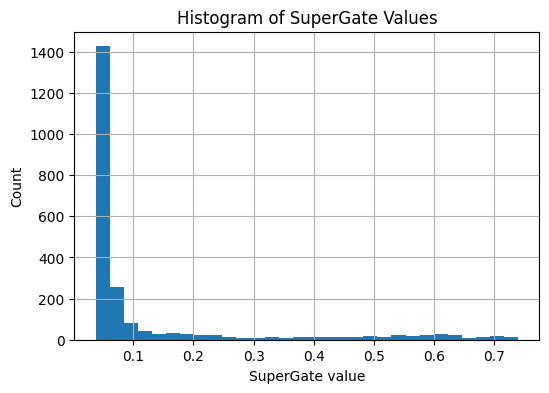

In [ ]:
import torch
import matplotlib.pyplot as plt

# Load saved supergates
supergates = torch.load("supergates.pt", map_location="cpu")

# Collect all gate values
all_gates = []
for name, g in supergates.items():
    all_gates.extend(g.detach().float().tolist())

all_gates = torch.tensor(all_gates)

# Plot histogram
plt.figure(figsize=(6, 4))
plt.hist(all_gates.numpy(), bins=30)
plt.xlabel("SuperGate value")
plt.ylabel("Count")
plt.title("Histogram of SuperGate Values")
plt.grid(True)
plt.savefig("histogram_of_gates.png", dpi=300, bbox_inches="tight")
plt.show()

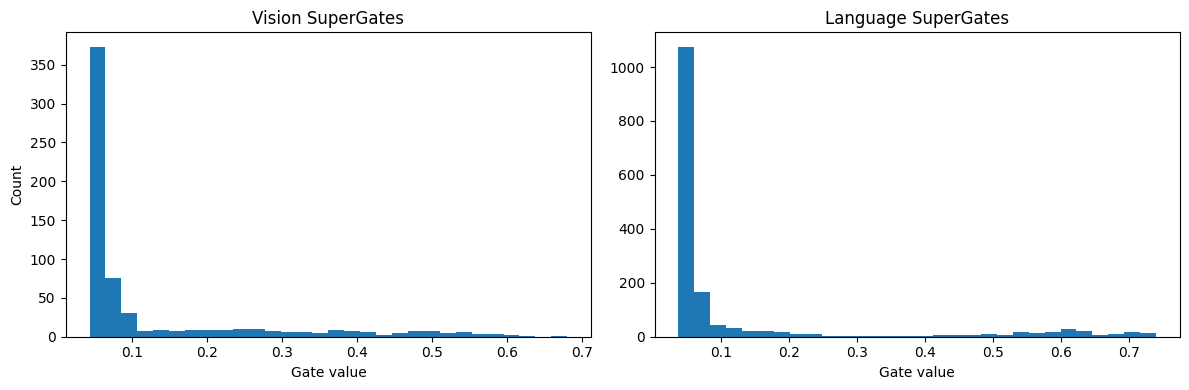

In [ ]:
vision_gates = []
language_gates = []

for name, g in supergates.items():
    if "vision" in name.lower():
        vision_gates.extend(g.detach().float().tolist())
    else:
        language_gates.extend(g.detach().float().tolist())

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(vision_gates, bins=30)
plt.title("Vision SuperGates")
plt.xlabel("Gate value")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.hist(language_gates, bins=30)
plt.title("Language SuperGates")
plt.xlabel("Gate value")

plt.tight_layout()
plt.savefig("vision_lang_gates.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
layer_name = list(supergates.keys())[0]  # or pick manually
g = supergates[layer_name].detach().float()

plt.figure(figsize=(5, 4))
plt.hist(g.numpy(), bins=10)
plt.title(f"SuperGates: {layer_name}")
plt.xlabel("Gate value")
plt.ylabel("Count")
plt.grid(True)
plt.savefig("supergates_k_proj", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
layer_entropy = []

for name, g in supergates.items():
    g = g.detach().float().cpu()
    p = g / (g.sum() + 1e-8)
    H = (-(p * torch.log(p + 1e-8))).sum().item()

    # crude depth extraction
    depth = int(name.split("layers.")[1].split(".")[0])
    layer_entropy.append((depth, H))

layer_entropy.sort()


In [ ]:
import matplotlib.pyplot as plt

d, h = zip(*layer_entropy)
plt.plot(d, h, marker="o")
plt.xlabel("Layer depth")
plt.ylabel("Gate entropy")
plt.title("Entropy vs Layer Depth")
plt.grid(True)
plt.savefig("entropy_layerdepth.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
import torch

# Load supergates
supergates = torch.load("supergates.pt", map_location="cpu")

# Containers
all_g = []
vision_g = []
language_g = []

# Collect gates
for name, g in supergates.items():
    g = g.detach().float().cpu()
    all_g.append(g)

    if "vision" in name.lower():
        vision_g.append(g)
    else:
        language_g.append(g)

# Summary function
def summarize(gs):
    g = torch.cat(gs)
    p = g / (g.sum() + 1e-8)
    return {
        "mean": g.mean().item(),
        "std": g.std().item(),
        "min": g.min().item(),
        "max": g.max().item(),
        "entropy": (-(p * torch.log(p + 1e-8))).sum().item()
    }

# Print summaries
print("ALL:", summarize(all_g))
print("VISION:", summarize(vision_g))
print("LANGUAGE:", summarize(language_g))


In [ ]:
nominal_rank = 8  # or 16 / 32 depending on run

eff_ranks = [(g > g.min() + 1e-4).sum().item() for g in all_g]
eff_ranks = torch.tensor(eff_ranks)

print("Avg effective rank:", eff_ranks.float().mean().item())
print("Compression ratio:", eff_ranks.float().mean().item() / nominal_rank)


In [ ]:
floor = min([g.min().item() for g in all_g])
g_all = torch.cat(all_g)

sparsity = (g_all <= floor + 1e-4).float().mean().item()
print(f"Sparsity: {sparsity * 100:.2f}%")
